In [1]:
%load_ext autoreload
%autoreload 2

In [5]:
import numpy as np
import xarray as xr

from fast_o3_iv import utils, plots
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc
import fast_o3_iv.attributable_fraction as af

In [6]:
config_hist_wa6 = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical', #historical
            variable_setname = 'setC',
            year_range = range(1975,2015) #range(1975,2015)
        )
config_hist_cesm2 = DatasetConfig(
            source_id = 'CESM2',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )

config_ssp245_wa6 = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'ssp245', #historical
            variable_setname = 'setC',
            year_range = range(2015,2055) #range(1975,2015)
        )
config_ssp245_cesm2 = DatasetConfig(
            source_id = 'CESM2',
            cmip_experiment_id = 'ssp245',
            variable_setname = 'setC',
            year_range = range(2015,2055)
        )

In [7]:
file_path = bc.return_osdma8_bc_path("inference", config_hist_wa6, "GPR-local")
wa6_hist_osdma = xr.open_dataset(file_path)

file_path = bc.return_osdma8_bc_path("inference", config_hist_cesm2, "GPR-local")
cesm2_hist_osdma = xr.open_dataset(file_path)

file_path = bc.return_osdma8_bc_path("inference", config_ssp245_wa6, "GPR-local")
wa6_ssp_osdma = xr.open_dataset(file_path)

file_path = bc.return_osdma8_bc_path("inference", config_ssp245_cesm2, "GPR-local")
cesm2_ssp_osdma = xr.open_dataset(file_path)

In [10]:
wa6_hist = wa6_hist_osdma['y_true_bc'].sel(time=slice('2005','2014'))
cesm2_hist = cesm2_hist_osdma['y_pred_bc'].sel(time=slice('2005','2014'))

wa6_ssp = wa6_ssp_osdma['y_true_bc'].sel(time=slice('2045','2054'))
cesm2_ssp = cesm2_ssp_osdma['y_pred_bc'].sel(time=slice('2045','2054'))

##############################
hist_af_bc = xr.concat(
    [
        wa6_hist.assign_coords(ensemble_member=np.arange(13)),
        cesm2_hist.assign_coords(ensemble_member=np.arange(13, 26)),
    ],
    dim="ensemble_member"
).rename("osdma_bc")

ds_hist = hist_af_bc.to_dataset()

################################
ssp_af_bc = xr.concat(
    [
        wa6_ssp.assign_coords(ensemble_member=np.arange(10)),
        cesm2_ssp.assign_coords(ensemble_member=np.arange(10, 26)),
    ],
    dim="ensemble_member"
).rename("osdma_bc")

ds_ssp = ssp_af_bc.to_dataset()

In [13]:
ds_hist_osdma_mean = ds_hist.mean(dim=['ensemble_member', 'time'])
ds_ssp_osdma_mean = ds_ssp.mean(dim=['ensemble_member', 'time'])

In [23]:
hist_af_healthrange = af.calc_af_range(ds_hist_osdma_mean,'osdma_bc')
ssp_af_healthrange = af.calc_af_range(ds_ssp_osdma_mean,'osdma_bc')

<xarray.Dataset> Size: 2MB
Dimensions:                 (lat: 144, lon: 288)
Coordinates:
  * lat                     (lat) float64 1kB -59.84 -58.9 ... 73.98 74.92
  * lon                     (lon) float64 2kB 0.0 1.25 2.5 ... 356.2 357.5 358.8
Data variables:
    osdma_bc_central_af     (lat, lon) float64 332kB 0.0 0.0 0.0 ... 6.103 6.152
    osdma_bc_low_af         (lat, lon) float64 332kB 0.0 0.0 0.0 ... 1.983 2.007
    osdma_bc_high_af        (lat, lon) float64 332kB 0.0 0.0 0.0 ... 11.95 12.02
    osdma_bc_rr_low_af      (lat, lon) float64 332kB 0.0 0.0 0.0 ... 2.903 2.927
    osdma_bc_rr_high_af     (lat, lon) float64 332kB 0.0 0.0 0.0 ... 9.186 9.258
    osdma_bc_tmrel_low_af   (lat, lon) float64 332kB 0.0 0.0 0.0 ... 7.977 8.025
    osdma_bc_tmrel_high_af  (lat, lon) float64 332kB 0.0 0.0 0.0 ... 4.19 4.24
Attributes:
    af:                            Attributable fraction (%) of COPD mortalit...
    units:                         percent
    health_relevant_ozone_metric:  OSDMA8
    methodology:                   GBD 2019-style COPD AF sensitivity calcula...
    central_tmrel_ppbv:            32.4
    central_rr_per_10ppbv:         1.063
    tmrel_range_ppbv:              29.1 to 35.7
    rr_range_per_10ppbv:           1.029 to 1.098
    note:                          low_af and high_af are bounding sensitivit...

In [26]:
file_path = af.return_af_path("inference", config_hist_wa6, "GPR-local")
wa6_hist_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_hist_cesm2, "GPR-local")
cesm2_hist_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_ssp245_wa6, "GPR-local")
wa6_ssp_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_ssp245_cesm2, "GPR-local")
cesm2_ssp_af = xr.open_dataset(file_path)

wa6_hist = wa6_hist_af['y_true_bc_af'].sel(time=slice('2005','2014'))
cesm2_hist = cesm2_hist_af['y_pred_bc_af'].sel(time=slice('2005','2014'))

wa6_ssp = wa6_ssp_af['y_true_bc_af'].sel(time=slice('2045','2054'))
cesm2_ssp = cesm2_ssp_af['y_pred_bc_af'].sel(time=slice('2045','2054'))

##############################
hist_af_bc = xr.concat(
    [
        wa6_hist.assign_coords(ensemble_member=np.arange(13)),
        cesm2_hist.assign_coords(ensemble_member=np.arange(13, 26)),
    ],
    dim="ensemble_member"
).rename("af_bc")

ds_hist_af = hist_af_bc.to_dataset()

################################
ssp_af_bc = xr.concat(
    [
        wa6_ssp.assign_coords(ensemble_member=np.arange(10)),
        cesm2_ssp.assign_coords(ensemble_member=np.arange(10, 26)),
    ],
    dim="ensemble_member"
).rename("af_bc")

ds_ssp_af = ssp_af_bc.to_dataset()

In [20]:
def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    # y < 0 pushes the colorbar below the axis
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

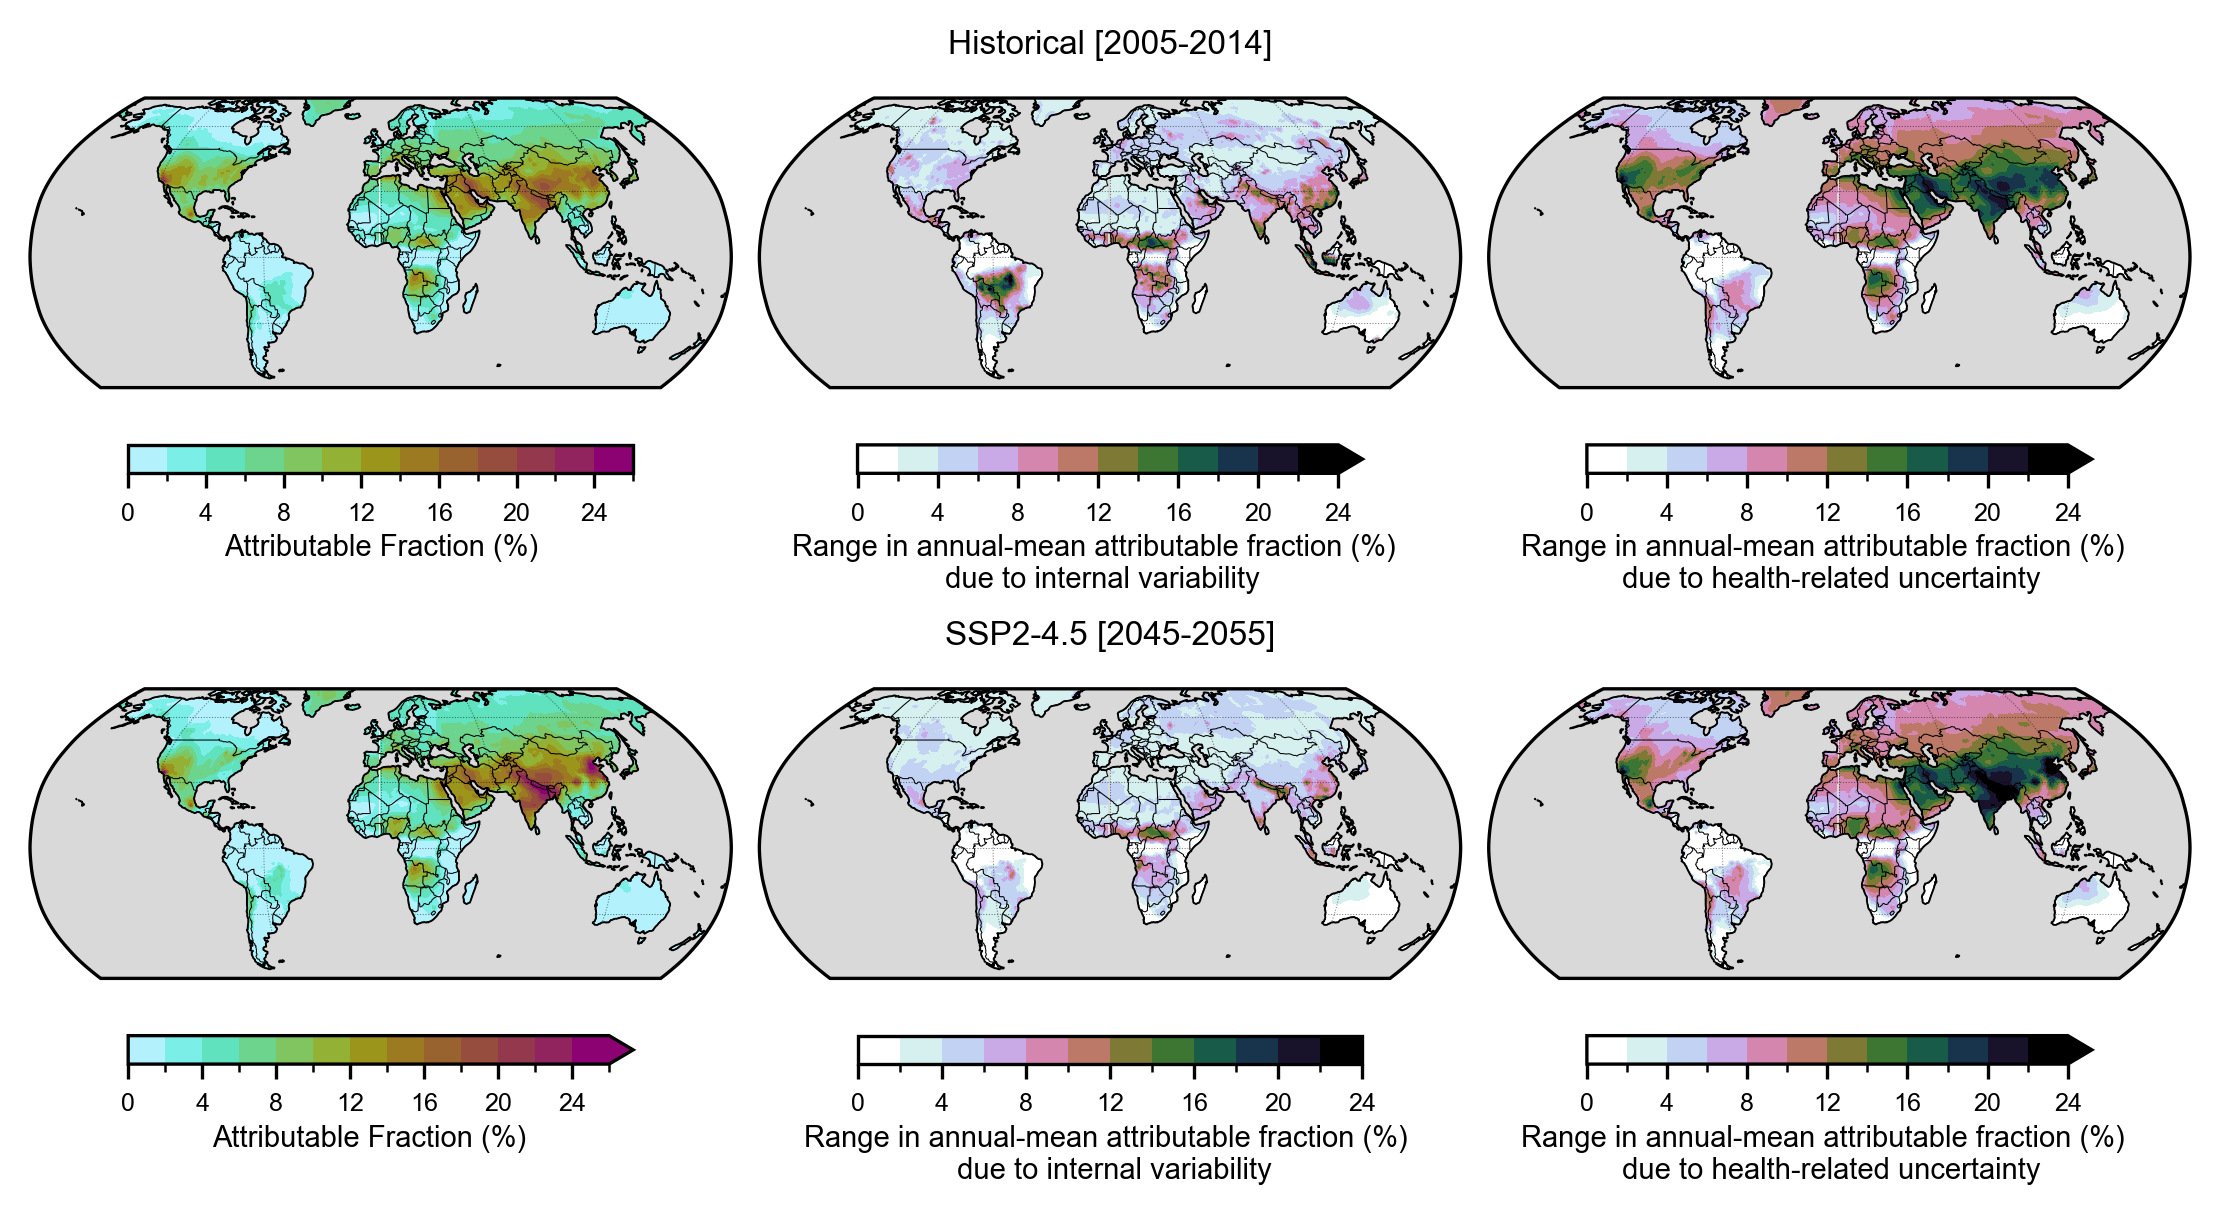

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import matplotlib.ticker as mticker

from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 9
fig_height_in = 4

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    2, 3,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.60, wspace=0.04
)        

proj = ccrs.Robinson(central_longitude=0)
# Column 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[1, 0], projection=proj)

# Column 2
ax3 = fig.add_subplot(gs1[0, 1], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

# Column 3
ax5 = fig.add_subplot(gs1[0, 2], projection=proj)
ax6 = fig.add_subplot(gs1[1, 2], projection=proj)

axes = [ax1, ax2, ax3, ax4, ax5, ax6]

titles= [None, None, "Historical [2005-2014]", "SSP2-4.5 [2045-2055]", None , None
         ]

for ax, t in zip(axes, titles):
    ax.set_title(t, color="black", fontsize=8)
    style_map(ax)

########################################################
### Attributable Fraction ####
vmax = 26
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.hawaii_r

colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF --- ##
z = hist_af_healthrange['osdma_bc_central_af']
m1 = z.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,         
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax1.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax1.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax1, m1, label="Attributable Fraction (%)")

## --- ssp AF --- ##
z = ssp_af_healthrange['osdma_bc_central_af']
m2 = z.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,          # or pass an explicit array of levels
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax2.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax2.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax2, m2, label="Attributable Fraction (%)")

##############################################################################
## Attributable Fraction RANGE INTVAR
vmax = 24
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['cubehelix_r']

colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF range --- ##
z_range = (
    ds_hist_af["af_bc"].max(dim=["ensemble_member", "time"])
    - ds_hist_af["af_bc"].min(dim=["ensemble_member", "time"])
)

m3 = z_range.plot.contourf(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax3.set_facecolor("0.85")

# cover oceans with gray
ax3.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax3.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax3, m3, label="Range in annual-mean attributable fraction (%) \n due to internal variability")


## --- ssp AF range --- ##
z_range = (
    ds_ssp_af["af_bc"].max(dim=["ensemble_member", "time"])
    - ds_ssp_af["af_bc"].min(dim=["ensemble_member", "time"])
)

m4 = z_range.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax4.set_facecolor("0.85")

# cover oceans with gray
ax4.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax4.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax4, m4, label="Range in annual-mean attributable fraction (%) \n due to internal variability")
##############################################################################

##############################################################################
## Attributable Fraction RANGE HEALTHVAR
vmax = 24
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['cubehelix_r']

colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF range --- ##

z_range = (
    hist_af_healthrange['osdma_bc_high_af']
    - hist_af_healthrange['osdma_bc_low_af']
)

m5 = z_range.plot.contourf(
    ax=ax5,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax5.set_facecolor("0.85")

# cover oceans with gray
ax5.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax5.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax5, m5, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty")


## --- ssp AF range --- ##
z_range = (
    ssp_af_healthrange['osdma_bc_high_af']
    - ssp_af_healthrange['osdma_bc_low_af']
)
m6 = z_range.plot.contourf(
    ax=ax6,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax6.set_facecolor("0.85")

# cover oceans with gray
ax6.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax6.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax6, m6, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty")
##############################################################################


for axes in [ax1, ax2, ax3, ax4, ax5, ax6]:
    plots.clip_to_obs_lat_band(axes, lat_min=-60, lat_max=75)


Text(0.48, 0.4192280795590202, 'SSP2-4.5 [2045–2055]')

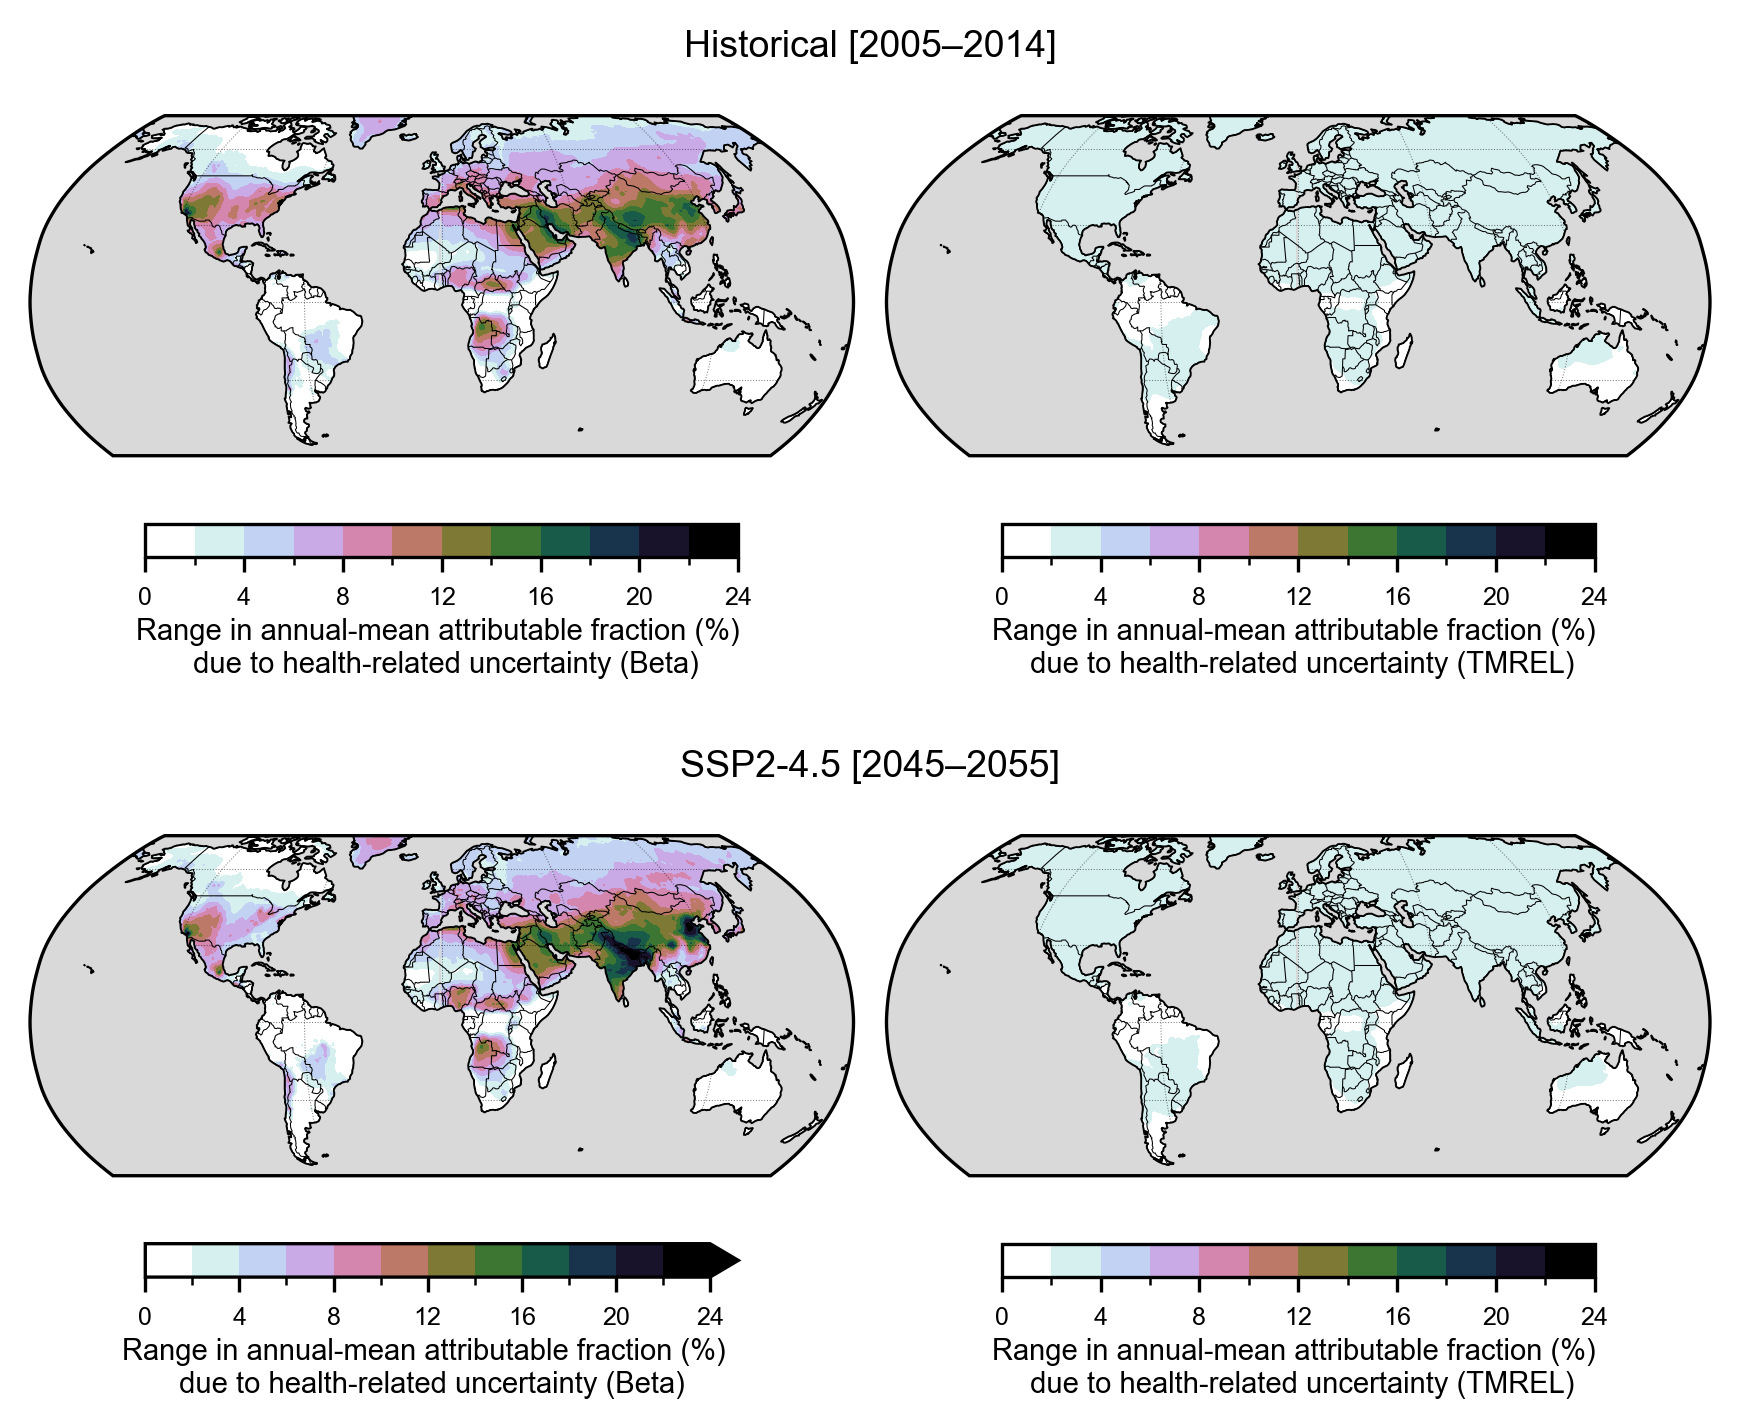

In [37]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import matplotlib.ticker as mticker

from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 7
fig_height_in = 5
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)
gs1 = GridSpec(
    2, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.5, wspace=0.04
)        
proj = ccrs.Robinson(central_longitude=0)
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[1, 0], projection=proj)
ax3 = fig.add_subplot(gs1[0, 1], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4]

titles= ["Historical [2005-2014]", "SSP2-4.5 [2045-2055]", None , None
         ]

for ax in axes:
    style_map(ax)


##############################################################################
##############################################################################
## Attributable Fraction RANGE HEALTHVAR BETA
vmax = 24
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['cubehelix_r']

colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF range --- ##

z_range = (
    hist_af_healthrange['osdma_bc_rr_high_af']
    - hist_af_healthrange['osdma_bc_rr_low_af']
)

m1 = z_range.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax1.set_facecolor("0.85")

# cover oceans with gray
ax1.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax1.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax1, m1, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (Beta)")


## --- ssp AF range --- ##
z_range = (
    ssp_af_healthrange['osdma_bc_rr_high_af']
    - ssp_af_healthrange['osdma_bc_rr_low_af']
)
m2 = z_range.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax2.set_facecolor("0.85")

# cover oceans with gray
ax2.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax2.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax2, m2, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (Beta)")
##############################################################################

## --- hist AF range --- ##

z_range = (
    hist_af_healthrange['osdma_bc_tmrel_low_af']
    - hist_af_healthrange['osdma_bc_tmrel_high_af']
)

m3 = z_range.plot.contourf(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax3.set_facecolor("0.85")

# cover oceans with gray
ax3.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax3.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax3, m3, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (TMREL)")


## --- ssp AF range --- ##
z_range = (
    ssp_af_healthrange['osdma_bc_tmrel_low_af']
    - ssp_af_healthrange['osdma_bc_tmrel_high_af']
)
m4 = z_range.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

ax4.set_facecolor("0.85")

# cover oceans with gray
ax4.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax4.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax4, m4, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (TMREL)")
##############################################################################



for ax in [ax1, ax2, ax3, ax4]:
    plots.clip_to_obs_lat_band(ax)

# centered row titles
top_left = ax1.get_position()
top_right = ax3.get_position()
bot_left = ax2.get_position()
bot_right = ax4.get_position()

x_top = 0.5 * (top_left.x0 + top_right.x1)
x_bot = 0.5 * (bot_left.x0 + bot_right.x1)

y_top = top_left.y1 + 0.02
y_bot = bot_left.y1 + 0.02

fig.text(
    x_top, y_top, "Historical [2005–2014]",
    ha="center", va="bottom", fontsize=9, color="black"
)

fig.text(
    x_bot, y_bot, "SSP2-4.5 [2045–2055]",
    ha="center", va="bottom", fontsize=9, color="black"
)
